<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/Week4a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly = pd.DataFrame({
    'month': months,
    'revenue_m': np.round(np.array([42, 45, 44, 50, 53, 51, 58, 61, 59, 66, 70, 78])
                          + rng.normal(0, 2, 12), 1),
})

regions = pd.DataFrame({
    'region': ['Lagos', 'Abuja', 'Kano', 'Ibadan', 'Port Harcourt'],
    'revenue_m': [12.5, 9.8, 8.4, 5.2, 11.1],
})

orders = pd.DataFrame({'units': rng.integers(1, 21, size=80)})
orders['revenue'] = np.round(
    orders['units'] * rng.normal(900, 150, size=80) + rng.normal(0, 800, size=80), -1
).clip(lower=100)
orders['order_value'] = np.round(rng.lognormal(8.2, 0.6, size=80), -1)

# Capture untouched copies
monthly_raw = monthly.copy()
regions_raw = regions.copy()
orders_raw = orders.copy()

### Notes & Predictions: Part A (Anatomy)

* **Object Type Prediction:** `type(fig)` will return `<class 'matplotlib.figure.Figure'>` (the outer canvas container), and `type(ax)` will return `<class 'matplotlib.axes._axes.Axes'>` (the individual plotting area containing the axes, ticks, and data lines).
* **Trend Expectation:** Monthly revenue starts around ₦42M in January and climbs steadily across the year to roughly ₦78M in December, with minor month-to-month noise.


=== PART A: ANATOMY ===


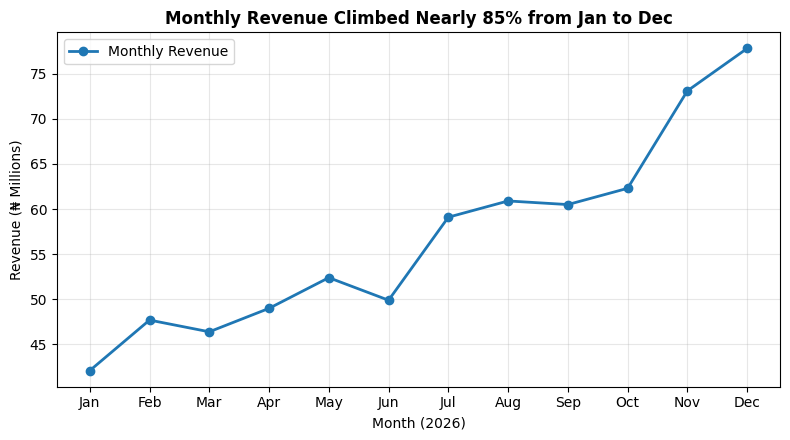

type(fig): <class 'matplotlib.figure.Figure'>
type(ax): <class 'matplotlib.axes._axes.Axes'>


In [23]:
print("=== PART A: ANATOMY ===")

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(monthly['month'], monthly['revenue_m'], marker='o', color='#1f77b4', linewidth=2, label='Monthly Revenue')
ax.set_title('Monthly Revenue Climbed Nearly 85% from Jan to Dec', fontsize=12, fontweight='bold')
ax.set_xlabel('Month (2026)')
ax.set_ylabel('Revenue (₦ Millions)')
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig('revenue_trend.png', dpi=200)
plt.show()

print("type(fig):", type(fig))
print("type(ax):", type(ax))


### Notes & Predictions: Part B (The Four One-Liners)

* **Scatter Prediction (`units` vs. `revenue`):** Strong **positive linear relationship**. Because revenue is generated directly from `units` multiplied by roughly ₦900 plus random noise, higher unit counts will move sharply upward in revenue with moderate vertical spread.
* **Histogram Prediction (`order_value` Mean vs. Median):** The **mean line will sit further to the right** than the median line. Because `order_value` follows a lognormal distribution, a long right tail of high-value orders pulls the mean upward while the median stays anchored at the 50th percentile.


=== PART B: THE THREE SINGLE-PANEL CHARTS ===


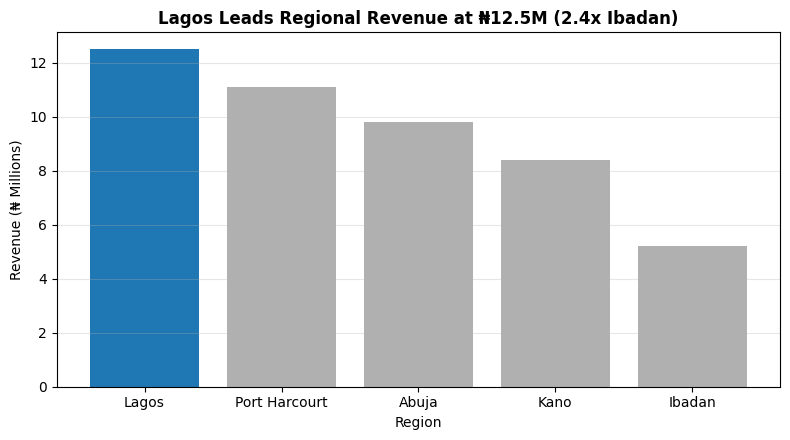

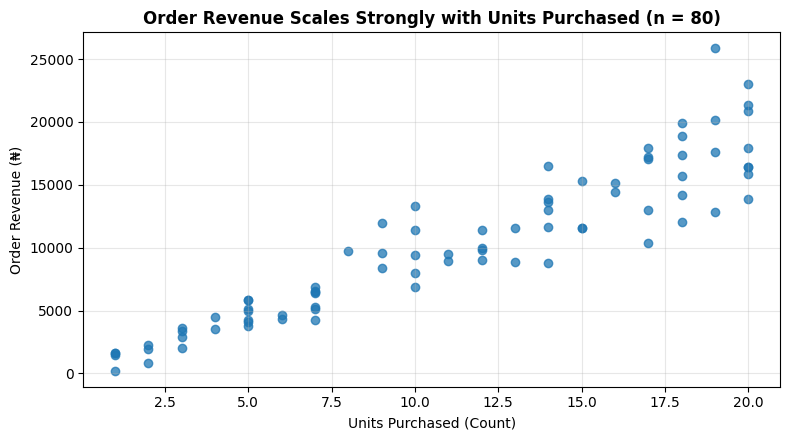

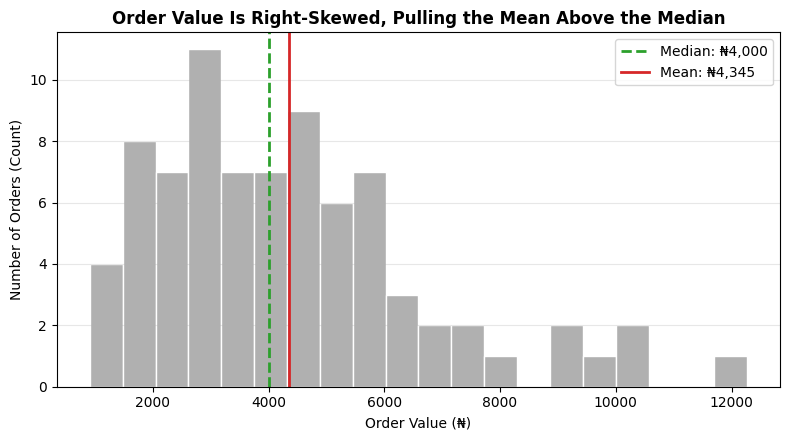

In [24]:
print("=== PART B: THE THREE SINGLE-PANEL CHARTS ===")

# 1. BAR CHART: Sorted highest to lowest with dynamic title from data
regions_sorted = regions.sort_values(by='revenue_m', ascending=False).reset_index(drop=True)
bar_colors = ['#1f77b4' if i == 0 else '#b0b0b0' for i in range(len(regions_sorted))]

top_reg = regions_sorted.iloc[0]
ibadan_rev = regions_sorted.loc[regions_sorted['region'] == 'Ibadan', 'revenue_m'].iloc[0]
ratio = top_reg['revenue_m'] / ibadan_rev
bar_title = f"{top_reg['region']} Leads Regional Revenue at ₦{top_reg['revenue_m']}M ({ratio:.1f}x Ibadan)"

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(regions_sorted['region'], regions_sorted['revenue_m'], color=bar_colors)
ax.set_title(bar_title, fontsize=12, fontweight='bold')
ax.set_xlabel('Region')
ax.set_ylabel('Revenue (₦ Millions)')
ax.grid(True, axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

# 2. SCATTER PLOT: Units against Revenue
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(orders['units'], orders['revenue'], color='#1f77b4', alpha=0.75)
ax.set_title('Order Revenue Scales Strongly with Units Purchased (n = 80)', fontsize=12, fontweight='bold')
ax.set_xlabel('Units Purchased (Count)')
ax.set_ylabel('Order Revenue (₦)')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# 3. HISTOGRAM: Order Value with Mean & Median Reference Lines
mean_val = orders['order_value'].mean()
med_val = orders['order_value'].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(orders['order_value'], bins=20, color='#b0b0b0', edgecolor='white')
ax.axvline(med_val, color='#2ca02c', linestyle='--', linewidth=2, label=f'Median: ₦{med_val:,.0f}')
ax.axvline(mean_val, color='#d62728', linestyle='-', linewidth=2, label=f'Mean: ₦{mean_val:,.0f}')
ax.set_title('Order Value Is Right-Skewed, Pulling the Mean Above the Median', fontsize=12, fontweight='bold')
ax.set_xlabel('Order Value (₦)')
ax.set_ylabel('Number of Orders (Count)')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
fig.tight_layout()
plt.show()


=== PART C: MULTIPLE PANELS ===


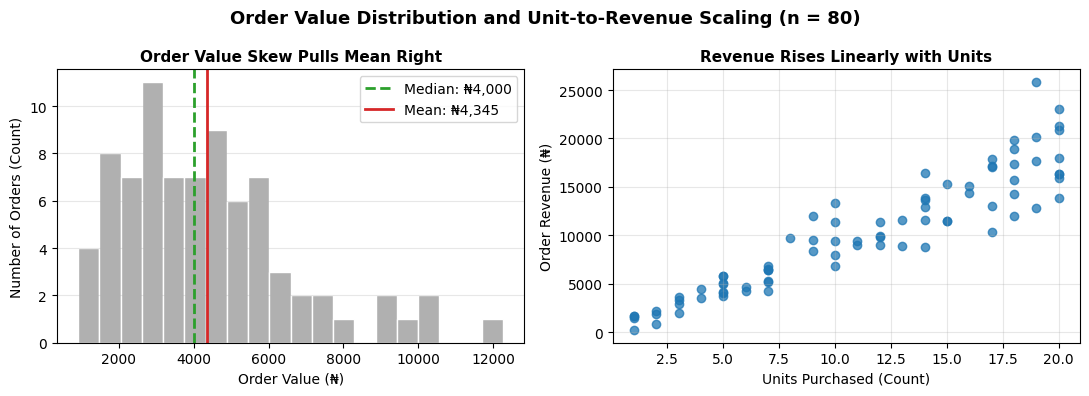

In [25]:
print("=== PART C: MULTIPLE PANELS ===")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left Panel: Histogram of order_value
axes[0].hist(orders['order_value'], bins=20, color='#b0b0b0', edgecolor='white')
axes[0].axvline(med_val, color='#2ca02c', linestyle='--', linewidth=2, label=f'Median: ₦{med_val:,.0f}')
axes[0].axvline(mean_val, color='#d62728', linestyle='-', linewidth=2, label=f'Mean: ₦{mean_val:,.0f}')
axes[0].set_title('Order Value Skew Pulls Mean Right', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Order Value (₦)')
axes[0].set_ylabel('Number of Orders (Count)')
axes[0].legend()
axes[0].grid(True, axis='y', alpha=0.3)

# Right Panel: Scatter of units vs revenue
axes[1].scatter(orders['units'], orders['revenue'], color='#1f77b4', alpha=0.75)
axes[1].set_title('Revenue Rises Linearly with Units', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Units Purchased (Count)')
axes[1].set_ylabel('Order Revenue (₦)')
axes[1].grid(True, alpha=0.3)

fig.suptitle('Order Value Distribution and Unit-to-Revenue Scaling (n = 80)', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig('order_panels.png', dpi=200)
plt.show()


=== PART D: CHALLENGE HELPER FUNCTION ===


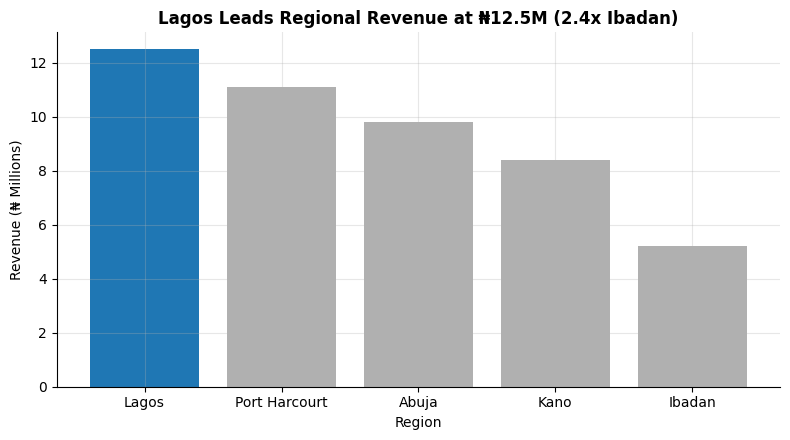

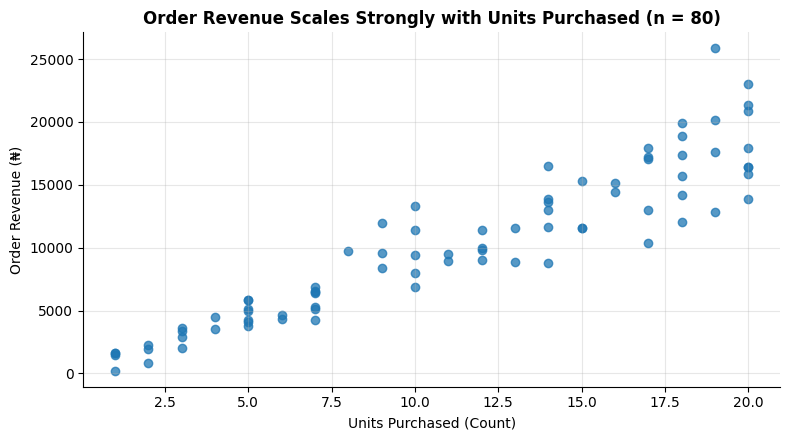

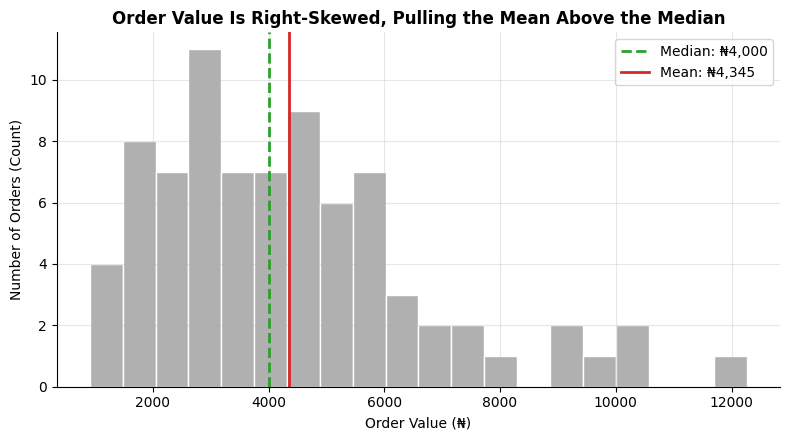

In [26]:
print("=== PART D: CHALLENGE HELPER FUNCTION ===")

def finish(ax, title, xlabel, ylabel):
    """
    Applies a finding-driven title, unit-labelled axes, a subtle grid,
    and clean top/right spine removal in one call.
    """
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Rebuild 1: Bar Chart using dynamic bar_title
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(regions_sorted['region'], regions_sorted['revenue_m'], color=bar_colors)
finish(ax, bar_title, 'Region', 'Revenue (₦ Millions)')
fig.tight_layout()
plt.show()

# Rebuild 2: Scatter Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(orders['units'], orders['revenue'], color='#1f77b4', alpha=0.75)
finish(ax, 'Order Revenue Scales Strongly with Units Purchased (n = 80)', 'Units Purchased (Count)', 'Order Revenue (₦)')
fig.tight_layout()
plt.show()

# Rebuild 3: Histogram
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(orders['order_value'], bins=20, color='#b0b0b0', edgecolor='white')
ax.axvline(med_val, color='#2ca02c', linestyle='--', linewidth=2, label=f'Median: ₦{med_val:,.0f}')
ax.axvline(mean_val, color='#d62728', linestyle='-', linewidth=2, label=f'Mean: ₦{mean_val:,.0f}')
finish(ax, 'Order Value Is Right-Skewed, Pulling the Mean Above the Median', 'Order Value (₦)', 'Number of Orders (Count)')
ax.legend()
fig.tight_layout()
plt.show()
